# Spectroscopy
This notebook is for getting the wavelengths of bands from an input spectrum image.

In [21]:
# imports
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

import skimage as ski
from skimage import io
from skimage.color import rgb2gray, label2rgb
from skimage.morphology import disk, binary_closing

from skimage.filters import try_all_threshold, threshold_mean, threshold_yen
from skimage.filters import threshold_triangle, threshold_isodata, threshold_li, threshold_otsu

from skimage import measure

import cv2

import rawpy

In [22]:
# background colour remover
def remove_background_col(img):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (30, 1))
    result_noback = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    return result_noback



In [23]:
# change from bgr to rgb format
def make_rgb_from_bgr(pic):
    if type(pic) == str:
    # .dng is in some funny looking matrix, need to convert it out
        with rawpy.imread(pic) as raw:
                # Postprocess converts the Bayer matrix into a standard 3-channel RGB image
                # half_size=True handles high-res files faster; set to False for maximum resolution
                rgb_img = raw.postprocess(use_camera_wb=True, half_size=False)

        return rgb_img
    else:
         return cv2.cvtColor(pic, cv2.COLOR_BGR2RGB)

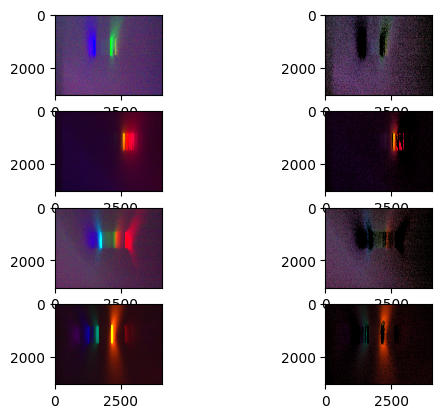

In [24]:
# isolating bands from background

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)
#print(picFiles_list)
for pic in picFiles_list:
    # getting the original pic out
    rgb_img = make_rgb_from_bgr(pic)
    img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2BGR)

    # use the background-removed image only to build a threshold mask
    img_noback = remove_background_col(img)
    img_gray = cv2.cvtColor(img_noback, cv2.COLOR_BGR2GRAY)

    # gaussian blur first to remove noise
    blur = cv2.GaussianBlur(img_gray, (7,7), 0)

    threshold = 10
    ret, img_thres = cv2.threshold(blur, threshold, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # keep selected pixels from the original color image
    bands_only = cv2.bitwise_and(rgb_img, rgb_img, mask=img_thres)

    plt.subplot(total,2,counter)
    plt.imshow(rgb_img)
    counter += 1
    plt.subplot(total,2,counter)
    plt.imshow(bands_only)
    counter += 1
